In [58]:
import pandas as pd

df_train = pd.read_csv("dataset_train.csv")
df_test = pd.read_csv("dataset_eval.csv")

df_train.head()

,Path,Effect
0,training_img/24-322.png,A
1,training_img/19-442.png,A
2,training_img/45-468.png,-1
3,training_img/44-315.png,B
4,training_img/45-27.png,B


In [59]:
from sklearn.preprocessing import LabelEncoder
enc = LabelEncoder()
df_train.Effect = enc.fit_transform(df_train.Effect)
df_train.head()

,Path,Effect
0,training_img/24-322.png,6
1,training_img/19-442.png,6
2,training_img/45-468.png,0
3,training_img/44-315.png,7
4,training_img/45-27.png,7


In [60]:
df_train.Effect.value_counts()

Effect
4    87
3    55
0    50
6    50
1    50
7    48
5    47
2    29
Name: count, dtype: int64

In [90]:
import torch

num_epochs = 40
batch_size = 32
learning_rate = 0.001

device = torch.device("cuda")
device

device(type='cuda')

In [91]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T

train_transforms = T.Compose([
    T.Resize((48, 48)),
    T.ToTensor()
])

test_transforms = T.Compose([
    T.Resize((48, 48)),
    T.ToTensor()
])

class MyDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        path = self.df.Path.iloc[idx]
        img = Image.open(path).convert("L")
        img = self.transform(img)
        label = torch.tensor(self.df.Effect.iloc[idx], dtype=torch.int64)
        return img, label

from sklearn.model_selection import train_test_split
df_1, df_2 = train_test_split(df_train, test_size=0.2, random_state=42)

train_dataset = MyDataset(df_1, train_transforms)
train_loader = DataLoader(train_dataset, batch_size=batch_size)

test_dataset = MyDataset(df_2, test_transforms)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

train_dataset[0][0][0][0][0]

tensor(1.)

In [92]:
train_dataset[21][0].shape

torch.Size([1, 48, 48])

In [97]:
import torch.nn as nn

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1),
            nn.BatchNorm2d(8),
            nn.ReLU(),
            nn.MaxPool2d(2,2),
        
            nn.Conv2d(8, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2,2),
        
            nn.Flatten(),
            nn.LazyLinear(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 8)
        )
    def forward(self, x):
        x = self.net(x)
        return x

model = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optim = torch.optim.AdamW(model.parameters(), lr=learning_rate)

model

CNN(
  (net): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Flatten(start_dim=1, end_dim=-1)
    (9): LazyLinear(in_features=0, out_features=64, bias=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=64, out_features=8, bias=True)
  )
)

In [98]:
def train(epoch):
    model.train()
    total_loss = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        loss = criterion(model(inputs), labels)
        optim.zero_grad()
        loss.backward()
        optim.step()
        total_loss += loss.item()
    if epoch % 5 == 0:
        print("Epoch ", epoch)
        print("Training Loss ", total_loss/len(train_loader))

def test(epoch):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            loss = criterion(model(inputs), labels)
            total_loss += loss.item()
    if epoch % 5 == 0:
        print("Validation Loss ", total_loss/len(test_loader))

In [99]:
for i in range(1, num_epochs+1):
    train(i)
    test(i)

Epoch  5
Training Loss  0.1198111931708726
Validation Loss  0.15685714284578958
Epoch  10
Training Loss  0.03064834309572523
Validation Loss  0.115240179002285
Epoch  15
Training Loss  0.015953922559591858
Validation Loss  0.04541081686814626
Epoch  20
Training Loss  0.011462466709252278
Validation Loss  0.10723018646240234
Epoch  25
Training Loss  0.01961523675444451
Validation Loss  0.08111473421255748
Epoch  30
Training Loss  0.006546552409417927
Validation Loss  0.08898545304934184
Epoch  35
Training Loss  0.007113770777571269
Validation Loss  0.08111858616272609
Epoch  40
Training Loss  0.003256148828024214
Validation Loss  0.07841656729578972


170.0
262.0
277.5
262.0
260.5
202.5


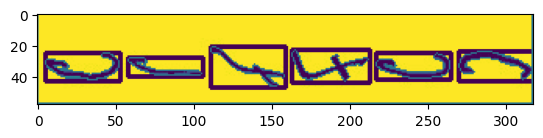

In [100]:
import matplotlib.pyplot as plt
import cv2 as cv

img1 = cv.imread(df_test.datapointID.iloc[15], cv.IMREAD_GRAYSCALE)
_, thresh = cv.threshold(img1,127,255,0)
contours, _ = cv.findContours(thresh, 1, 2)

min_area = 50
max_area = 700
for cnt in contours:
    if cv.contourArea(cnt) > min_area and cv.contourArea(cnt) < max_area:
        print(cv.contourArea(cnt))
        x,y,w,h = cv.boundingRect(cnt)
        rect = cv.rectangle(img1,(x,y),(x+w,y+h),(0,255,0),2)

cv.drawContours(img1, contours, -1, (100, 100, 100), 1)
plt.imshow(img1)

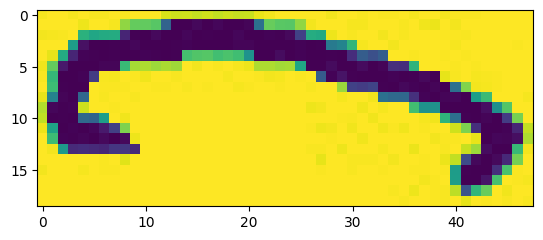

In [101]:
cnt = contours[3]
x,y,w,h = cv.boundingRect(cnt)
img1 = cv.imread(df_test.datapointID.iloc[15], cv.IMREAD_GRAYSCALE)
patch = img1[y:y+h, x:x+w]
plt.imshow(patch)

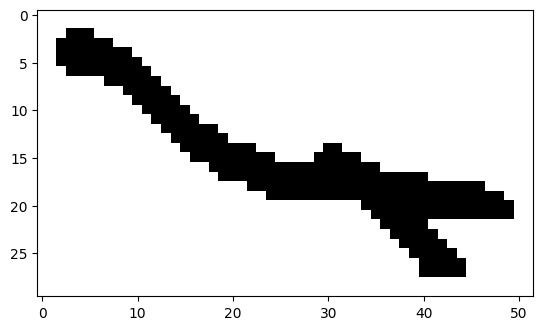

In [102]:
import numpy as np

def rem_bg(img):
    _, img = cv.threshold(img, 120, 255, cv.THRESH_BINARY)
    blur = cv.GaussianBlur(img, (3, 3), cv.BORDER_DEFAULT)
    thresh = cv.adaptiveThreshold(blur, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 15, 10)
    return thresh

def get_patches(path):
    img = cv.imread(path, cv.IMREAD_GRAYSCALE)
    img = rem_bg(img)

    thresh = cv.adaptiveThreshold(img, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY_INV, 15, 10)
    contours, _ = cv.findContours(thresh,cv.RETR_EXTERNAL,cv.CHAIN_APPROX_SIMPLE)

    patches = []
    for cnt in contours:
        x, y, w, h = cv.boundingRect(cnt)
        if w * h < 100:
            continue
        pad = 2
        x1 = x - pad
        y1 = y - pad
        x2 = x + w + pad
        y2 = y + h + pad
        patch = img[y1:y2, x1:x2]
        patches.append((x1, patch))

    if len(patches) == 0:
        return [img]
    patches = [p for _, p in sorted(patches, key=lambda x: x[0])]
    return patches

patches = get_patches(df_test.datapointID[15])
plt.imshow(patches[2], cmap='grey')

In [103]:
final_transforms = T.Compose([
    T.ToPILImage(),
    T.Resize((48, 48)),
    T.ToTensor()
])

model = model.to("cpu")
model.eval()
with torch.no_grad():
    x = final_transforms(patches[2]).unsqueeze(0)
    pred = torch.argmax(model(x), dim=1)
    pred = enc.inverse_transform(pred)
    print(pred[0])

B


In [104]:
def enc_preds(predictions):
    if not predictions:
        return ""

    result = []
    for i, pred in enumerate(predictions):
        if i == 0:
            result.append(0 if pred in ["A", "B"] else int(pred))
        else:
            if pred in ["A", "B"]:
                result.append(result[-1])
            else:
                result.append(result[-1] + int(pred))

    return "|".join(map(str, result))

In [105]:
from tqdm import tqdm

preds = []

for path in tqdm(df_test.datapointID):
    patches = get_patches(path)
    full_pred = []
    for patch in patches:
        with torch.no_grad():
            x = final_transforms(patch).unsqueeze(0)
            pred = torch.argmax(model(x), dim=1)
            pred = enc.inverse_transform(pred)[0]
            full_pred.append(pred)
    preds.append(enc_preds(full_pred))

preds[:5]

100%|████████████████████████████████████████████████████████████████████████████████| 328/328 [00:04<00:00, 72.29it/s]


['4', '1', '4', '1|5|6|7', '1|5|6|7|7|7|7|7|7']

In [106]:
df_preds = pd.DataFrame({
    "subtaskID": 1,
    "datapointID": df_test.datapointID,
    "answer": preds
})

df_preds

,subtaskID,datapointID,answer
0,1,eval_img/12.png,4
1,1,eval_img/14.png,1
2,1,eval_img/19.png,4
3,1,eval_img/20.png,1|5|6|7
4,1,eval_img/23.png,1|5|6|7|7|7|7|7|7
...,...,...,...
323,1,eval_img/s11r.png,1|2|3|4|5|6|7|8|9|10|11
324,1,eval_img/s12r.png,1|2|3|4|5|6|7|8|9|10|11|12
325,1,eval_img/s13r.png,1|2|3|4|5|6|7|8|9|10|11|12|13
326,1,eval_img/s14r.png,1|2|3|4|5|6|7|8|9|10|11|12|13|14


In [107]:
df_preds.to_csv("submission.csv", index=False)